#### ▶ 비선형 이진 분류(동심원 데이터)

In [132]:
import torch
import matplotlib.pyplot as plt

#### Step 1. 데이터 생성

In [133]:
N = 100

radius1 = 0.3 + 0.05*torch.randn(int(N/2), 1)  # 0.3주변의 값(50)
radius2 = 1 + 0.01*torch.randn(int(N/2), 1)  # 1주변의(50)

# 각도 만들기
theta1 = 2 * torch.pi * torch.rand(int(N/2),1) - torch.pi  # -파이 ~ 파이 의 값 
theta2 = 2 * torch.pi * torch.rand(int(N/2),1) - torch.pi

# (x,y) 좌표로 바꾸기. 극좌표를 직교좌표로 변환
class1_data = torch.hstack([radius1*torch.cos(theta1), radius1*torch.sin(theta1)])
class2_data = torch.hstack([radius2*torch.cos(theta2), radius2*torch.sin(theta2)])

class1_label = torch.ones(int(N/2),1)
class2_label = torch.zeros(int(N/2),1)

X = torch.vstack([class1_data, class2_data])
y = torch.vstack([class1_label, class2_label])


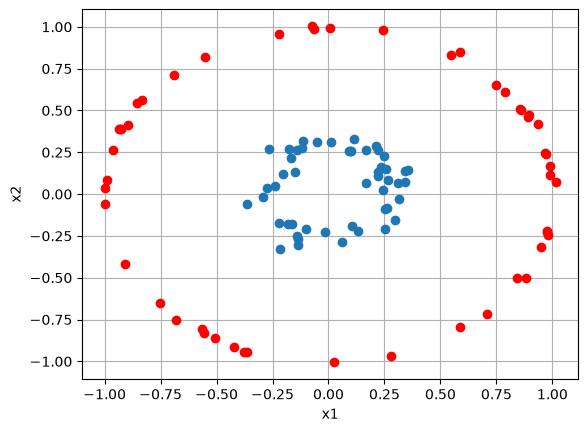

In [134]:
plt.plot(class1_data[:,0], class1_data[:,1],'o')
plt.plot(class2_data[:,0], class2_data[:,1], 'ro')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid()

#### Step 2. 모델 만들기

In [135]:
from torch import nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        # self.linear = nn.Sequential(nn.Linear(2, 1000),
        #                             nn.Sigmoid(),
        #                             nn.Linear(1000, 1),
        #                             nn.Sigmoid()
        # )

        # 선형분류에서만 가능
        # self.linear = nn.Sequential(nn.Linear(2, 1),
        #                             nn.Sigmoid(),
        # )

        # self.linear = nn.Sequential(nn.Linear(2, 100),
        #                             nn.Sigmoid(),
        #                             nn.Linear(100, 100),
        #                             nn.Sigmoid(),
        #                             nn.Linear(100, 100),
        #                             nn.Sigmoid(),
        #                             nn.Linear(100, 1),
        #                             nn.Sigmoid(),
        # )

        # self.linear = nn.Sequential(nn.Linear(2, 100),
        #                             nn.Sigmoid(),
        #                             nn.Linear(100, 100),
        #                             nn.Sigmoid(),
        #                             *[nn.Sequential(nn.Linear(100,100), nn.Sigmoid()) for _ in range(10)],
        #                             nn.Linear(100, 1),
        #                             nn.Sigmoid(),
        # )

        self.linear = nn.Sequential(nn.Linear(2, 100),
                                    nn.ReLU(),
                                    *[nn.Sequential(nn.Linear(100,100), nn.ReLU()) for _ in range(10)],
                                    nn.Linear(100, 1),
                                    nn.Sigmoid(),
        )

    def forward(self, x):
        x = self.linear(x)
        return x

In [136]:
model = MLP()

#### Step 3. 모델 학습 시키기

In [137]:
from torch import optim

# LR = 1e-1
# EPOCH = 100
LR = 1e-4
EPOCH = 300

optimizer = optim.Adam(model.parameters(), lr=LR)
# optimizer = optim.SGD(model.parameters(), lr=LR)  # 선형이 아니라 잘 안됨
cirterion = nn.BCELoss()

loss_history=[]

model.train()  # train모드로 변환
for ep in range(EPOCH) :
    # inference
    y_hat = model(X)

    # loss
    loss = cirterion(y_hat, y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history += [loss.item()]

    # print
    print(f'EPOCH : {ep+1}, Train Loss : {loss.item():.4f}')
    print('-'*20)

EPOCH : 1, Train Loss : 0.6937
--------------------
EPOCH : 2, Train Loss : 0.6936
--------------------
EPOCH : 3, Train Loss : 0.6936
--------------------
EPOCH : 4, Train Loss : 0.6936
--------------------
EPOCH : 5, Train Loss : 0.6935
--------------------
EPOCH : 6, Train Loss : 0.6935
--------------------
EPOCH : 7, Train Loss : 0.6935
--------------------
EPOCH : 8, Train Loss : 0.6934
--------------------
EPOCH : 9, Train Loss : 0.6934
--------------------
EPOCH : 10, Train Loss : 0.6934
--------------------
EPOCH : 11, Train Loss : 0.6934
--------------------
EPOCH : 12, Train Loss : 0.6934
--------------------
EPOCH : 13, Train Loss : 0.6933
--------------------
EPOCH : 14, Train Loss : 0.6933
--------------------
EPOCH : 15, Train Loss : 0.6933
--------------------
EPOCH : 16, Train Loss : 0.6933
--------------------
EPOCH : 17, Train Loss : 0.6933
--------------------
EPOCH : 18, Train Loss : 0.6932
--------------------
EPOCH : 19, Train Loss : 0.6932
--------------------
EP

Text(0, 0.5, 'Loss')

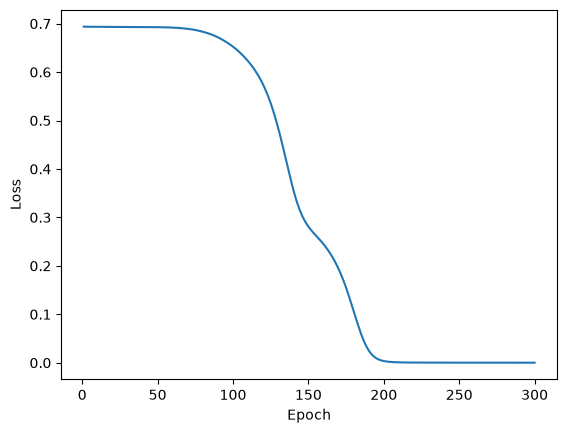

In [138]:
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')

#### Step 4. 모델 테스트

Text(0.5, 0.5, 'x2')

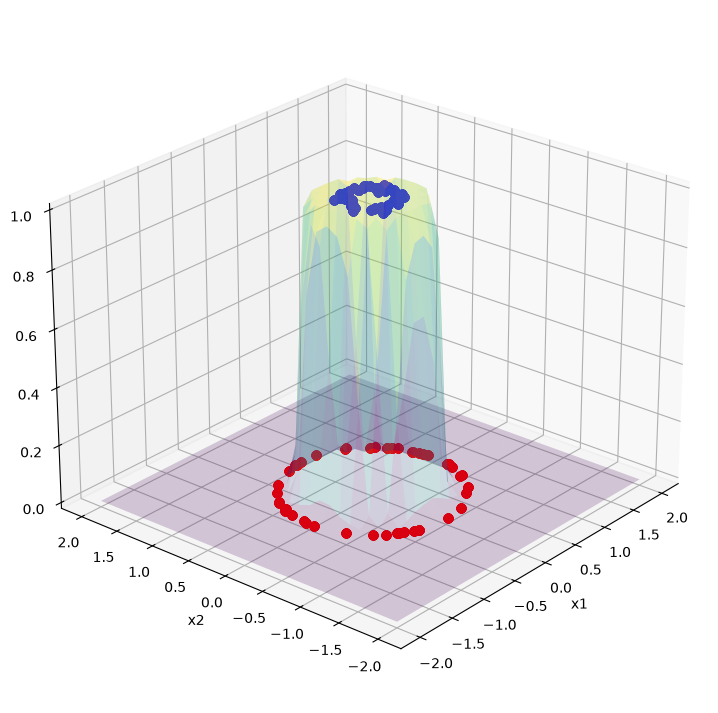

In [139]:
x1_test = torch.linspace(-2, 2, 30)
x2_test = torch.linspace(-2, 2, 30)

X1_test, X2_test = torch.meshgrid(x1_test, x2_test)
X_test = torch.cat([X1_test.unsqueeze(dim=2), X2_test.unsqueeze(dim=2)], dim=2)

model.eval()  # test mode로 변환
with torch.no_grad() :
    y_hat = model(X_test)

Y_hat = y_hat.squeeze()

plt.figure(figsize=(10,9))
ax = plt.axes(projection = '3d')
ax.view_init(elev=25, azim = -140)

ax.plot_surface(X1_test, X2_test, Y_hat.numpy(), cmap='viridis', alpha=0.2)
plt.plot(class1_data[:,0], class1_data[:,1] ,class1_label, 'bo')
plt.plot(class2_data[:,0], class2_data[:,1] ,class2_label, 'ro')
plt.xlabel('x1')
plt.ylabel('x2')